In [1]:
import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.sparse as sp
import SPACEL
from SPACEL import Scube

In [2]:
import scanpy as sc 

#run using env_stalign from here
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

refExpression = pd.read_csv('refSubAD_expression.csv', index_col=0)
queryExpression = pd.read_csv('querySubAD_expression.csv', index_col=0)
refObs = pd.read_csv('refSubAD_obs.csv', index_col=0)
queryObs = pd.read_csv('querySubAD_obs.csv', index_col=0)

refAD = ad.AnnData(X=refExpression.values, obs=refObs)
queryAD = ad.AnnData(X=queryExpression.values, obs=queryObs)

refAD.var_names = refExpression.columns
queryAD.var_names = queryExpression.columns

# sc.pp.normalize_total(refAD, target_sum=1e2)
# sc.pp.normalize_total(queryAD, target_sum=1e2)
# sc.pp.log1p(refAD)
# sc.pp.log1p(queryAD)
queryAD.obs['spatial_domain_original'] = queryAD.obs['spatial_domain'].copy()
refAD.obs['spatial_domain_original'] = refAD.obs['spatial_domain'].copy()
sc.pp.scale(refAD)
sc.pp.scale(queryAD)

/home/adyprat/anaconda3/envs/SPACEL/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/adyprat/anaconda3/envs/SPACEL/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [3]:
queryAD

AnnData object with n_obs × n_vars = 4671 × 16
    obs: 'Image', 'Object ID', 'Object type', 'Name', 'Classification', 'Parent', 'ROI', 'Centroid X µm', 'Centroid Y µm', 'Nucleus: Area', 'Nucleus: Perimeter', 'Nucleus: Circularity', 'Nucleus: Max caliper', 'Nucleus: Min caliper', 'Nucleus: Eccentricity', 'Nucleus: DAPI sum', 'Nucleus: DAPI std dev', 'Nucleus: DAPI max', 'Nucleus: DAPI min', 'Nucleus: DAPI range', 'Nucleus: CD8 sum', 'Nucleus: CD8 std dev', 'Nucleus: CD8 max', 'Nucleus: CD8 min', 'Nucleus: CD8 range', 'Nucleus: CD20 sum', 'Nucleus: CD20 std dev', 'Nucleus: CD20 max', 'Nucleus: CD20 min', 'Nucleus: CD20 range', 'Nucleus: CD4 sum', 'Nucleus: CD4 std dev', 'Nucleus: CD4 max', 'Nucleus: CD4 min', 'Nucleus: CD4 range', 'Nucleus: GZMB sum', 'Nucleus: GZMB std dev', 'Nucleus: GZMB max', 'Nucleus: GZMB min', 'Nucleus: GZMB range', 'Nucleus: FOXP3 sum', 'Nucleus: FOXP3 std dev', 'Nucleus: FOXP3 max', 'Nucleus: FOXP3 min', 'Nucleus: FOXP3 range', 'Nucleus: Ki67 sum', 'Nucleus: Ki

In [4]:
refAD.obsm['initAlign'] = refAD.obs[['New_X','New_Y']].values
queryAD.obsm['initAlign'] = queryAD.obs[['New_X','New_Y']].values



refAD.obsm['spatial'] = refAD.obsm['initAlign'].copy()
queryAD.obsm['spatial'] = queryAD.obsm['initAlign'].copy()


In [5]:
from SPACEL import Splane, Spoint

Splane.utils.add_cell_type_composition(refAD, celltype_anno=refAD.obs['CellType'])
Splane.utils.add_cell_type_composition(queryAD, celltype_anno=queryAD.obs['CellType'])

adata_list = [refAD, queryAD]

splane_model = Splane.init_model(adata_list, n_clusters=4, k=2, gnn_dropout=0.8, use_gpu=True)


Global seed set to 0


Setting global seed: 42
Calculating cell type weights...
Generating GNN inputs...
Calculating largest eigenvalue of normalized graph Laplacian...


/home/adyprat/anaconda3/envs/SPACEL/lib/python3.8/site-packages/SPACEL/Splane/pygcn_utils.py:11: RuntimeWarning: divide by zero encountered in power
  d = sp.diags(np.power(np.array(adj.sum(1)), -1).flatten(), 0)


Calculating Chebyshev polynomials up to order 2...


In [6]:
splane_model.train(d_l=0.2)
splane_model.identify_spatial_domain()

Setting the weight of similarity loss to 2.440


The best epoch 30 total loss=-2.667 g loss=-2.524 d loss=0.717 d acc=0.597 simi loss=-0.988 db loss=0.533:  28%|██▊       | 85/300 [00:22<00:56,  3.79it/s]

Stop trainning because of loss convergence


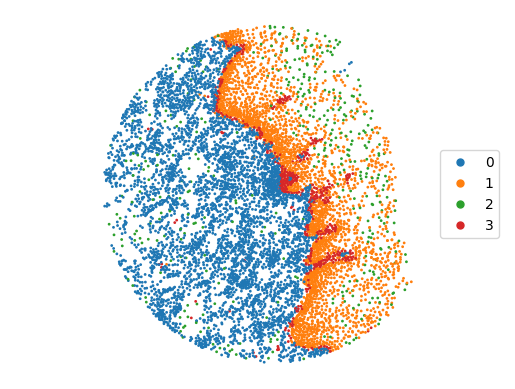

In [7]:
Scube.plot_stacked_slices(adata_list,spatial_key='spatial',cluster_key='spatial_domain')

In [8]:
Scube.align(adata_list,
      cluster_key='spatial_domain', 
      n_neighbors = 24, 
      raw_loc_key = 'initAlign',
      n_threads=10,
      p=2,
      a=1,
      write_loc_path='Scube_outputs/prna_aligned_coordinates.csv'
     )

Start alignment...
Alignment slice 1 to 0
Runtime: 22.567506790161133 s


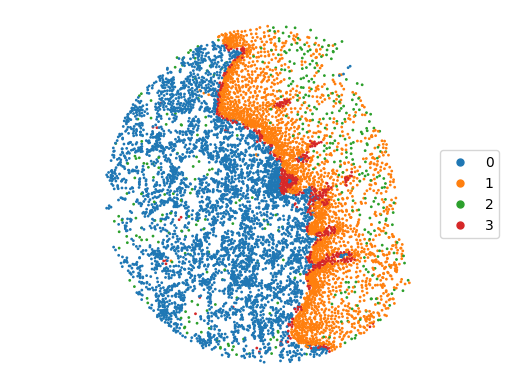

In [9]:
Scube.plot_stacked_slices(adata_list,spatial_key='spatial_aligned',cluster_key='spatial_domain')


In [10]:
import numpy as np
from scipy.spatial import cKDTree

# Get coordinates from refAD and queryAD using the 'spatial_aligned' key
ref_coords = refAD.obsm['spatial_aligned']
query_coords = queryAD.obsm['spatial_aligned']

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Optionally, print or summarize the results
print(f"Number of matches: {np.sum(matches)} / {len(matches)}")
print(f"Match percentage: {np.mean(matches)*100:.2f}%")




Number of matches: 3008 / 4671
Match percentage: 64.40%


In [11]:
refAD.obs['spatial_domain_SPACEL'] = refAD.obs['spatial_domain'].copy()
queryAD.obs['spatial_domain_SPACEL'] = queryAD.obs['spatial_domain'].copy()

refAD.obs['spatial_domain'] = refAD.obs['spatial_domain_original'].copy()
queryAD.obs['spatial_domain'] = queryAD.obs['spatial_domain_original'].copy()



In [12]:
refAD.obsm['X_SPACEL_spatial'] = refAD.obsm['spatial_aligned'].copy()
refAD.write_h5ad('ref_SPACEL_RNA_tongue.h5ad')
queryAD.obsm['X_SPACEL_spatial'] = queryAD.obsm['spatial_aligned'].copy()
queryAD.write_h5ad('query_SPACEL_Prot_tongue.h5ad')